In [25]:
%load_ext cuml.accel
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kartik2112/fraud-detection")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/fraud-detection


In [3]:
df_train = pd.read_csv(path + "/fraudTrain.csv")
df_test = pd.read_csv(path + "/fraudTest.csv")

In [4]:
numerical_cols = ['amt', 'city_pop', 'unix_time', 'distance', 'hour', 'day_of_week', 'month']
categorical_cols = ['category']

In [5]:
def add_features(df):
    df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
    df['hour'] = df['trans_date_trans_time'].dt.hour
    df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
    df['month'] = df['trans_date_trans_time'].dt.month

    def haversine(lat1, lon1, lat2, lon2):
        R = 6371  # Earth's radius in km
        lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
        dlat = lat2 - lat1
        dlon = lon2 - lon1
        a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
        c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
        return R * c

    df['distance'] = haversine(df['lat'], df['long'], df['merch_lat'], df['merch_long'])
    return df

In [6]:
df_train = add_features(df_train)
df_test = add_features(df_test)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ])

In [8]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('isolation_forest', IsolationForest(contamination=0.01, random_state=42))  # contamination is the expected proportion of anomalies
])

In [9]:
X_train = df_train[numerical_cols + categorical_cols]
pipeline.fit(X_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amt', 'city_pop',
                                                   'unix_time', 'distance',
                                                   'hour', 'day_of_week',
                                                   'month']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['category'])])),
                ('isolation_forest',
                 IsolationForest(contamination=0.01, random_state=42))])

In [10]:
df_train['is_anomaly'] = pipeline.predict(X_train)
df_train['is_anomaly'] = df_train['is_anomaly'] == -1

In [11]:
X_test = df_test[numerical_cols + categorical_cols]
df_test['is_anomaly'] = pipeline.predict(X_test)
df_test['is_anomaly'] = df_test['is_anomaly'] == -1  # Convert to True (anomaly) / False (normal)


In [18]:
anomaly_scores = -pipeline.decision_function(X_test)

In [12]:
print("Sample of test set anomaly detection results:")
print(df_test[['amt', 'hour', 'category', 'is_anomaly', 'is_fraud']].head(10))
print("\nNumber of anomalies detected in test set:", df_test['is_anomaly'].sum())
print("Number of actual fraud cases in test set:", df_test['is_fraud'].sum())


Sample of test set anomaly detection results:
      amt  hour        category  is_anomaly  is_fraud
0    2.86    12   personal_care       False         0
1   29.84    12   personal_care       False         0
2   41.28    12  health_fitness       False         0
3   60.05    12        misc_pos       False         0
4    3.19    12          travel       False         0
5   19.55    12       kids_pets       False         0
6  133.93    12  health_fitness       False         0
7   10.37    12   personal_care       False         0
8    4.37    12    shopping_pos       False         0
9   66.54    12     food_dining       False         0

Number of anomalies detected in test set: 10116
Number of actual fraud cases in test set: 2145


In [20]:
print("\nClassification Report (Anomaly as Fraud Prediction on Test Set):")
print(classification_report(df_test['is_fraud'], df_test['is_anomaly'], target_names=['Not Fraud', 'Fraud']))
roc_auc = roc_auc_score(df_test['is_fraud'], -anomaly_scores)  # Use negative scores for ROC-AUC
print("ROC-AUC Score on Test Set:", roc_auc)



Classification Report (Anomaly as Fraud Prediction on Test Set):
              precision    recall  f1-score   support

   Not Fraud       1.00      0.98      0.99    553574
       Fraud       0.07      0.34      0.12      2145

    accuracy                           0.98    555719
   macro avg       0.53      0.66      0.55    555719
weighted avg       0.99      0.98      0.99    555719

ROC-AUC Score on Test Set: 0.16835023722052378


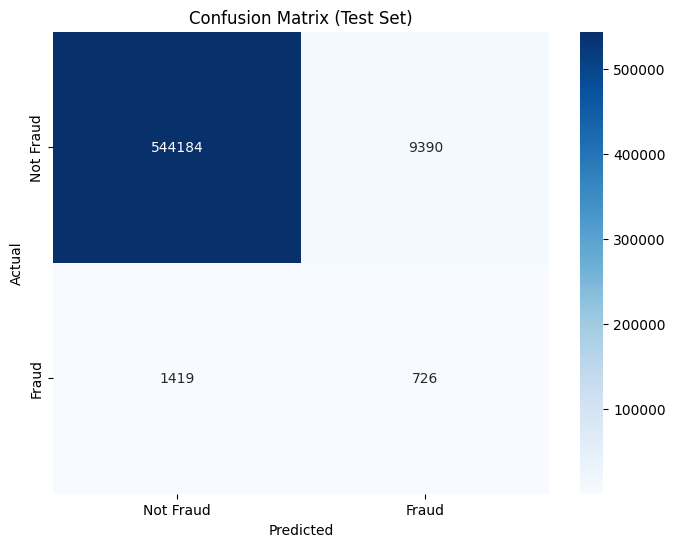

In [16]:
cm = confusion_matrix(df_test['is_fraud'], df_test['is_anomaly'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


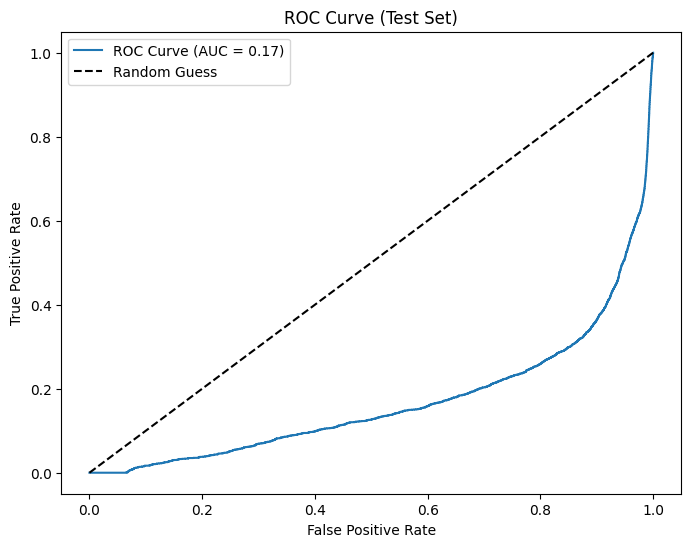

In [21]:
fpr, tpr, _ = roc_curve(df_test['is_fraud'], -anomaly_scores)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Test Set)')
plt.legend()
plt.show()

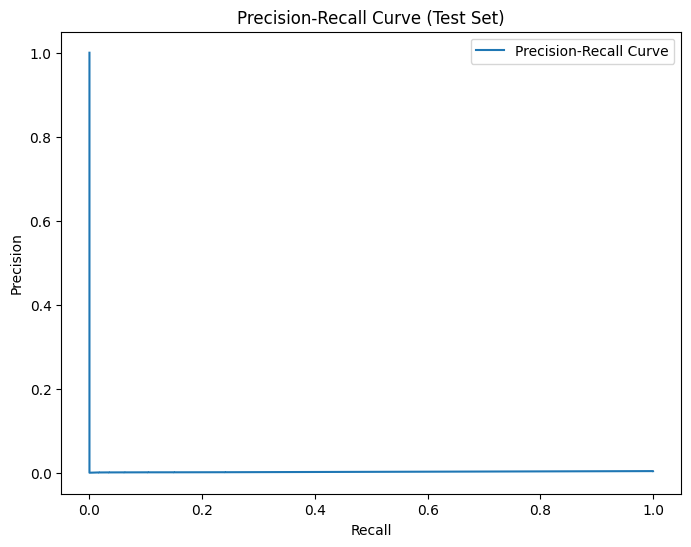

In [22]:
precision, recall, _ = precision_recall_curve(df_test['is_fraud'], -anomaly_scores)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label='Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Test Set)')
plt.legend()
plt.show()

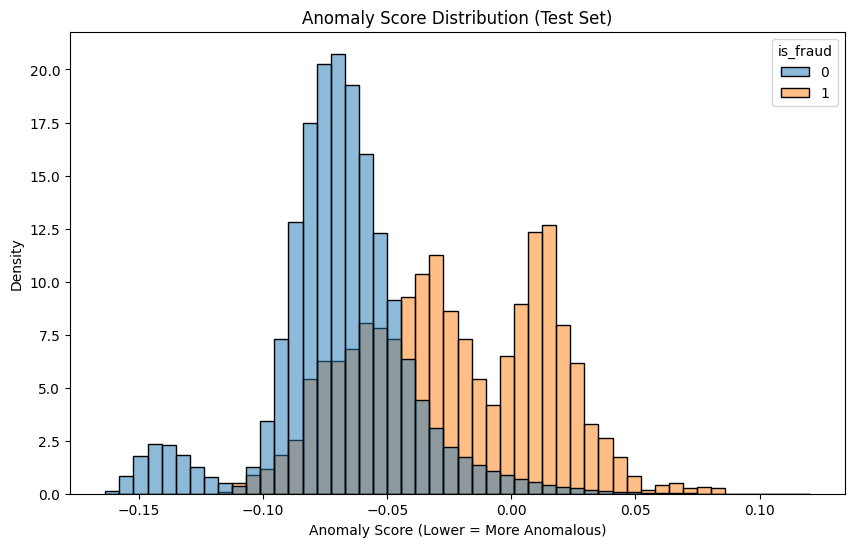

In [23]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_test, x=anomaly_scores, hue='is_fraud', bins=50, stat='density', common_norm=False)
plt.xlabel('Anomaly Score (Lower = More Anomalous)')
plt.ylabel('Density')
plt.title('Anomaly Score Distribution (Test Set)')
plt.show()

In [26]:
joblib.dump(pipeline, 'isolation_forest_fraud_model.joblib')
print("Model saved as 'isolation_forest_fraud_model.joblib'")

Model saved as 'isolation_forest_fraud_model.joblib'
